## HW-3

Задача основана на реальных данных. В этой задаче мы проанализируем изменение индекса качества воздуха (air quality index, AQI) для двух мегаполисов Индии за последние годы. Данные взяты с Kaggle (https://www.kaggle.com/rohanrao/air-quality-data-in-india)

In [1]:
# !gdown https://drive.google.com/uc?id=1hvODMPkJPe0HLIGq8RgClN1_RSw2gfD-

**Задание 1.**

Загрузите файл `city_day.csv`. Нам понадобятся столбцы `City`, `Date` и `AQI`. При этом учтите, что:
* В дальнейшем мы будем работать с датами, поэтому используйте аргумент `parse_dates` чтобы корректо их распарсить
* Данные содержат пропуски, которые нужно удалить

Для удобства сохраните в отдельные поля `Month` и `Year` соответственно год и месяц, когда производились замеры

Нас будут интересовать два города: Мумбаи (Mumbai) и Калькутта (Kolkata). Сохраните данные по этим двум городам для всех днней с 1 июля 2018 года включительно

In [2]:
import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from typing import Callable, Dict, List, Tuple, Optional

In [3]:
data = pd.read_csv('city_day.csv', parse_dates=['Date'])

In [4]:
data.sample(5)

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
822,Ahmedabad,2017-04-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14273,Guwahati,2019-08-29,20.83,35.25,3.76,9.24,16.06,5.79,0.52,11.79,12.59,87.29,NaN,NaN,41.0,Good
13968,Gurugram,2020-03-13,60.57,182.58,13.32,30.60,30.07,32.89,0.84,12.68,40.26,2.45,3.18,7.03,134.0,Moderate
17390,Jaipur,2019-08-26,19.12,47.48,9.62,28.33,31.24,38.26,0.64,9.80,26.62,0.36,3.68,NaN,61.0,Satisfactory
13078,Gurugram,2017-10-05,79.04,NaN,1.51,17.30,20.05,NaN,0.13,5.45,75.54,0.00,4.44,NaN,196.0,Moderate


In [5]:
df = data[['City', 'Date', 'AQI']].copy()
df.dropna(subset=['AQI'], inplace=True)

In [6]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

In [7]:
df.sample(5)

,City,Date,AQI,Year,Month
27970,Thiruvananthapuram,2020-03-25,68.0,2020,3
23335,Mumbai,2019-01-20,234.0,2019,1
29195,Visakhapatnam,2019-08-01,113.0,2019,8
26136,Talcher,2018-04-03,99.0,2018,4
14016,Gurugram,2020-04-30,141.0,2020,4


In [8]:
mumbai = df[(df['City'] == 'Mumbai') & (df['Date'] >= '2018-07-01')].copy()
kolkata = df[(df['City'] == 'Kolkata') & (df['Date'] >= '2018-07-01')].copy()

In [9]:
mumbai.head()

,City,Date,AQI,Year,Month
23132,Mumbai,2018-07-01,88.0,2018,7
23133,Mumbai,2018-07-02,77.0,2018,7
23134,Mumbai,2018-07-03,89.0,2018,7
23135,Mumbai,2018-07-04,75.0,2018,7
23136,Mumbai,2018-07-05,68.0,2018,7


In [10]:
kolkata.head()

,City,Date,AQI,Year,Month
19114,Kolkata,2018-07-01,58.0,2018,7
19115,Kolkata,2018-07-02,62.0,2018,7
19116,Kolkata,2018-07-03,50.0,2018,7
19117,Kolkata,2018-07-04,58.0,2018,7
19118,Kolkata,2018-07-05,57.0,2018,7


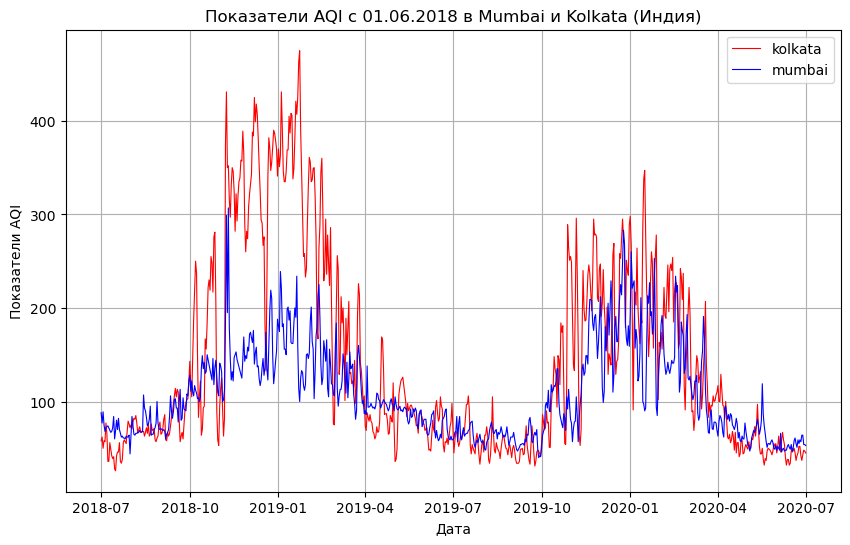

In [11]:
# линейный график (опционально для себя)
plt.figure(figsize=(10,6))
plt.plot(kolkata['Date'], kolkata['AQI'], 'r-', lw=0.8, label='kolkata')
plt.plot(mumbai['Date'], mumbai['AQI'], 'b-', lw=0.8, label='mumbai')
plt.title('Показатели AQI с 01.06.2018 в Mumbai и Kolkata (Индия)')
plt.xlabel('Дата')
plt.ylabel('Показатели AQI')
plt.legend()
plt.grid()
plt.show()

**Задание 2.**

В предыдущих задачах мы строили доверительные интервалы в предположении, что выборка взята из параметрического семейства распределений. Но что делать в случае, когда подобное предположение сделать нельзя? Оказывается, в этом случае можно строить доверительный интервал с помощью бутстрепа.

Ниже формальное опредлеение доверительного интервала. Если выглядит не понятно, давайте обсудим на занятии. Но вообще по сути мы так же строили доверительный интервал на занятии.

Пусть $X_1, \dots, X_n$ — выборка, для которой мы хотим оценить некоторую величину $\theta$. Построим $k$ бутстепных выборок, и получим по ним оценки $\theta^*_1, \dots, \theta^*_k$. Отсортируем их, чтобы получить вариационный ряд $\theta^*_{(1)}, \dots, \theta^*_{(k)}$. Тогда получим, что
$$
C^* = \left(\theta^*_{(\lfloor k (1 + \alpha) / 2 \rfloor)},
\theta^*_{(\lceil k (1 - \alpha) / 2 \rceil)} \right)
$$
будет (приблизительным) доверительным интервалом для $\theta$ уровня доверия $\alpha$.

Для каждого месяца с июля 2018 по июнь 2020 включтельно постройте бутстрепный доверительный интервал для __среднего значения AQI__. В этом вам помогут следующие вспомогательные функции (но не обязательно следовать им):

In [12]:
def get_dataset_by_month(
    df: pd.DataFrame,
    year: int,
    month: int
):
    """ Сохранение в массив данные для указанного месяца и года."""
    sample = np.array(df[(df['Year'] == year) & (df['Month'] == month)]['AQI'])
    return sample    

In [13]:
def get_bootstrap_samples(
    sample: np.ndarray,
    k: int = 1000
):
    """ Построение k бутстрепных выборок для указанной выборки. """
    
    bootstrap_samples = []
    
    for _ in range(k):
        bootstrap_sample = np.random.choice(sample, size=len(sample), replace=True)
        bootstrap_samples.append(bootstrap_sample)
        
    return bootstrap_samples

In [14]:
def bootstrap_conf_interval(
    sample: np.ndarray,
    estimator: Callable = lambda x: np.mean(x, axis=-1),
    alpha: float = 0.95,
    k: int = 1000
):
    """ Построение бутстрепных доверительных интервалов. """
    bootstrap_samples = get_bootstrap_samples(sample, k=k) # получили 1000 бутстреп выборок

    bootstrap_estimates = []
    for bootstrap_sample in bootstrap_samples:
        bootstrap_estimates.append(estimator(bootstrap_sample))

    ci_lower = np.percentile(bootstrap_estimates, (1-alpha)/2 * 100)
    ci_upper = np.percentile(bootstrap_estimates, (alpha + (1-alpha)/2) * 100)

    return ci_lower, ci_upper

In [15]:
def compute_city_confidence_intervals(
    city_df: pd.DataFrame,
    city_name: str,
    start_date: str = '2018-07-01',
    end_date: str = '2020-06-30',
    alpha: float = 0.95,
    n_bootstrap: int = 1000
):
    """ Вычисление бутстрепных доверительных интервалов по каждому городу и месяцу года. """
    
    # Создаем список месяцев
    date_range = pd.date_range(start=start_date, end=end_date, freq='MS')
    
    results = {
        'city': city_name,
        'dates': [],
        'means': [],
        'ci_lower': [],
        'ci_upper': [],
        'months': []
    }
          
    for date in date_range:
        year = date.year
        month = date.month
        month_key = f"{year}-{month:02d}"
        
        # Получаем выборку для месяца
        sample = get_dataset_by_month(city_df, year, month)
        
        # Вычисляем доверительный интервал
        ci_lower, ci_upper = bootstrap_conf_interval(sample, alpha=alpha, k=n_bootstrap)
        
        results['dates'].append(date)
        results['months'].append(month_key)
        results['means'].append(np.mean(sample))
        results['ci_lower'].append(ci_lower)
        results['ci_upper'].append(ci_upper)
                        
    return results

In [16]:
 # Вычисляем доверительные интервалы для каждого города
mumbai_results = compute_city_confidence_intervals(mumbai, 'Mumbai')
kolkata_results = compute_city_confidence_intervals(kolkata, 'Kolkata')

In [17]:
pd.DataFrame(mumbai_results).head()

,city,dates,means,ci_lower,ci_upper,months
0,Mumbai,2018-07-01,69.172414,65.723276,72.621552,2018-07
1,Mumbai,2018-08-01,74.806452,70.870161,79.000806,2018-08
2,Mumbai,2018-09-01,87.233333,81.698333,92.769167,2018-09
3,Mumbai,2018-10-01,122.461538,116.650962,128.541346,2018-10
4,Mumbai,2018-11-01,155.461538,139.151923,174.593269,2018-11


In [18]:
pd.DataFrame(kolkata_results).head()

,city,dates,means,ci_lower,ci_upper,months
0,Kolkata,2018-07-01,51.612903,46.512097,56.581452,2018-07
1,Kolkata,2018-08-01,70.322581,68.000000,72.678226,2018-08
2,Kolkata,2018-09-01,83.066667,76.265000,90.568333,2018-09
3,Kolkata,2018-10-01,163.064516,138.191129,186.290323,2018-10
4,Kolkata,2018-11-01,283.666667,245.632500,316.002500,2018-11


**Задание 3.**

Постройте на одном графике доверительные интервалы для Мумбаи и Калькутты. Также отметьте точками на графике истинный средний AQI и соедините точки линиями. Проследите за тем, чтобы графики, относящиеся к одному городу, были одного цвета.

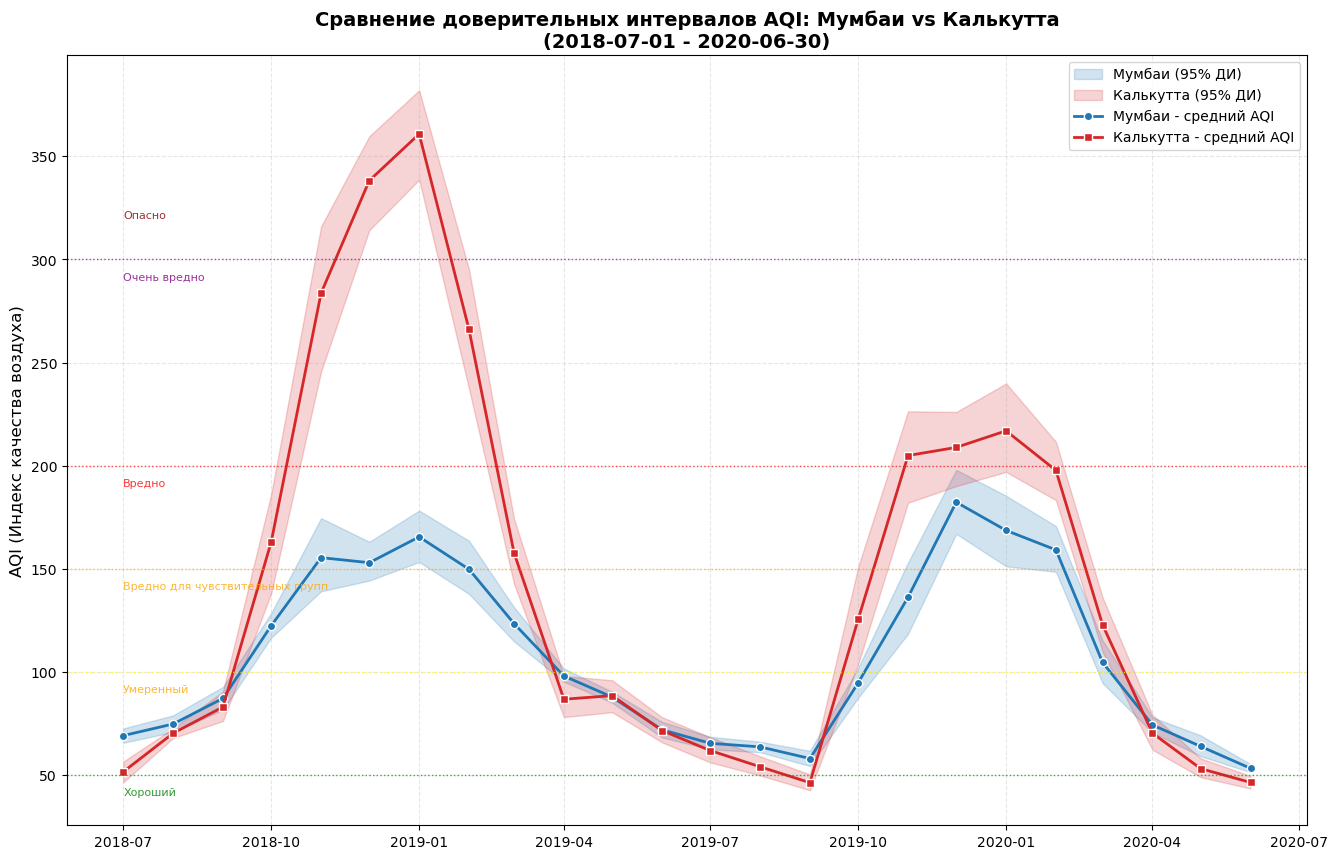

In [31]:
# Строит график доверительных интервалов для Мумбаи и Калькутты. 
    
# Цвета для городов
city_colors = {
    'Mumbai': '#1f77b4',
    'Kolkata': '#d62728'
}

fig = plt.figure(figsize=(16, 10))
ax = plt.subplot()
    
# Доверительный интервал (закрашенная область)
ax.fill_between(
    mumbai_results['dates'],
    mumbai_results['ci_lower'],
    mumbai_results['ci_upper'],
    alpha=0.2,
    color=city_colors['Mumbai'],
    label='Мумбаи (95% ДИ)'
)
ax.fill_between(
    kolkata_results['dates'],
    kolkata_results['ci_lower'],
    kolkata_results['ci_upper'],
    alpha=0.2,
    color=city_colors['Kolkata'],
    label='Калькутта (95% ДИ)'
)
    
# Средние значения с точками и линией
ax.plot(
    mumbai_results['dates'],
    mumbai_results['means'],
    color=city_colors['Mumbai'],
    linewidth=2,
    marker='o',
    markersize=6,
    label='Мумбаи - средний AQI',
    markeredgecolor='white',
    markeredgewidth=1
)
ax.plot(
    kolkata_results['dates'],
    kolkata_results['means'],
    color=city_colors['Kolkata'],
    linewidth=2,
    marker='s',
    markersize=6,
    label='Калькутта - средний AQI',
    markeredgecolor='white',
    markeredgewidth=1
)

ax.set_ylabel('AQI (Индекс качества воздуха)', fontsize=12)
ax.set_title(f'Сравнение доверительных интервалов AQI: Мумбаи vs Калькутта\n({'2018-07-01'} - {'2020-06-30'})', 
              fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, linestyle='--')

# Добавляем линии качества воздуха
ax.axhline(y=50, color='green', alpha=0.7, linestyle=':', linewidth=1, label='_nolegend_')
ax.axhline(y=100, color='yellow', alpha=0.7, linestyle=':', linewidth=1, label='_nolegend_')
ax.axhline(y=150, color='orange', alpha=0.7, linestyle=':', linewidth=1, label='_nolegend_')
ax.axhline(y=200, color='red', alpha=0.7, linestyle=':', linewidth=1, label='_nolegend_')
ax.axhline(y=300, color='purple', alpha=0.7, linestyle=':', linewidth=1, label='_nolegend_')
    
# Добавляем текстовые подписи для уровней качества
ax.text(pd.to_datetime('2018-07-01'), 40, 'Хороший', fontsize=8, color='green', alpha=0.8)
ax.text(pd.to_datetime('2018-07-01'), 90, 'Умеренный', fontsize=8, color='orange', alpha=0.8)
ax.text(pd.to_datetime('2018-07-01'), 140, 'Вредно для чувствительных групп', fontsize=8, color='orange', alpha=0.8)
ax.text(pd.to_datetime('2018-07-01'), 190, 'Вредно', fontsize=8, color='red', alpha=0.8)
ax.text(pd.to_datetime('2018-07-01'), 290, 'Очень вредно', fontsize=8, color='purple', alpha=0.8)
ax.text(pd.to_datetime('2018-07-01'), 320, 'Опасно', fontsize=8, color='maroon', alpha=0.8)

ax.legend()
plt.savefig('air_quality_di.png')  # сохраняем
plt.show()

In [20]:
# Выводим статистику
print("\n" + "="*50)
print("СВОДНАЯ СТАТИСТИКА")
print("="*50)

for city_results in [mumbai_results, kolkata_results]:
    print(f"\n{city_results['city']}:")
    print(f"  Средний AQI: {np.mean(city_results['means']):.1f} ± {np.std(city_results['means']):.1f}")
    print(f"  Минимальный среднемесячный AQI: {np.min(city_results['means']):.1f}")
    print(f"  Максимальный среднемесячный AQI: {np.max(city_results['means']):.1f}")
    print(f"  Средняя ширина ДИ: {np.mean(np.array(city_results['ci_upper']) - np.array(city_results['ci_lower'])):.1f}")



СВОДНАЯ СТАТИСТИКА

Mumbai:
  Средний AQI: 107.6 ± 40.7
  Минимальный среднемесячный AQI: 53.3
  Максимальный среднемесячный AQI: 182.3
  Средняя ширина ДИ: 15.7

Kolkata:
  Средний AQI: 143.0 ± 94.3
  Минимальный среднемесячный AQI: 46.4
  Максимальный среднемесячный AQI: 360.8
  Средняя ширина ДИ: 27.5


**Задание 4.**

Посмотрите на получившийся график. Видны ли в нем какие-либо закономерности? С чем они могут быть связаны?

**Ответ:**

На графике прослеживается закономерность повышения уровня AQI с октября по март каждого года.

Я думаю основную роль здесь играют муссоны — сезонные ветры, которые кардинально меняют погодные условия. С октября по март дует сухой северо-восточный муссон, а с июня по сентябрь — влажный юго-западный, приносящий обильные дожди. Вместе с этим к октябрю, окончивается сезон дождей и жара, и наступает более прохладная и комфортная температура (25-28С) и сухой воздух. Также именно в этот период в Индии начинается туристический сезон, огромный наплым туристов, транспорта, что ведет за собой увеличение количества выхлопных газов.

А также Калькутта и Мумбаи — крупнейшие промышленные центры Индии. Мумбаи доминирует в нефтепереработке, финансах, киноиндустрии и портовой деятельности. Калькутта исторически развита в черной металлургии, машиностроении, джутовой и пищевой промышленности. Оба города — важнейшие узлы обрабатывающей промышленности. 

Основные отрасли промышленности:

Мумбаи (Бомбей):

- Нефтепереработка и газ: Крупнейший район добычи и переработки.
- Финансы и бизнес: Финансовая столица, штаб-квартиры крупных компаний.
- Портовая деятельность: Крупнейший морской узел.
- Текстильная, пищевая и химическая промышленность.

Калькутта:

- Тяжелое машиностроение и металлургия: Центр черной металлургии.
- Джутовая промышленность: Исторически ведущий центр.
- Горнодобывающая промышленность: Рядом находится плато Чхота-Нагпур, богатое углем и рудой.
- Фармацевтика, электроника и пищевая промышленность. 

Калькутта остается ключевым промышленным узлом востока, а Мумбаи — главным экономическим центром на западе Индии.

Скорее всего эти факторы: погодные условия, наплыв туристов и крупная промышленность в совокупности играют ключевую роль на показатели качества воздуха. В Калькутте из-за черной металлургии соответственно эти показатели выше.

**Задание 5.**

Теперь давайте сравним качество воздуха в апреле 2019 и апреле 2020 годов. Постройте __на одном графике__
* доверительные интервалы для апреля 2019 и апреля 2020 для Мумбаи
* истинные средние значения (с помощью `plt.hlines`)
* точки выборки

Проследите за тем, чтобы графики, относящиеся к одному городу, были одного цвета.

То же самое сделайте для Калькутты.

In [21]:
# ДИ и means для Мумбаи
mumbai_results_df = pd.DataFrame(mumbai_results)

mumbai_years19 = mumbai_results_df[mumbai_results_df['dates']=='2019-04-01']
mumbai_years20 = mumbai_results_df[mumbai_results_df['dates']=='2020-04-01']


In [22]:
mumbai_years19

,city,dates,means,ci_lower,ci_upper,months
9,Mumbai,2019-04-01,98.066667,95.299167,101.7,2019-04


In [23]:
mumbai_years20

,city,dates,means,ci_lower,ci_upper,months
21,Mumbai,2020-04-01,74.333333,70.6325,78.034167,2020-04


In [24]:
# ДИ и means для Колькутта
kolkata_results_df = pd.DataFrame(kolkata_results)

kolkata_years19 = kolkata_results_df[kolkata_results_df['dates']=='2019-04-01']
kolkata_years20 = kolkata_results_df[kolkata_results_df['dates']=='2020-04-01']

In [25]:
kolkata_years19

,city,dates,means,ci_lower,ci_upper,months
9,Kolkata,2019-04-01,86.8,78.13,98.0675,2019-04


In [26]:
kolkata_years20

,city,dates,means,ci_lower,ci_upper,months
21,Kolkata,2020-04-01,70.366667,62.298333,79.2,2020-04


In [27]:
# Получаем данные AQI для Мумбаи
mumbai_year19_sample = get_dataset_by_month(mumbai, 2019, 4)
mumbai_year20_sample = get_dataset_by_month(mumbai, 2020, 4)
mumbai_year19_sample

array([ 90.,  86., 138.,  94.,  94.,  95.,  98.,  95.,  93.,  94.,  92.,
        96., 109., 108., 102., 101.,  93.,  96.,  99., 102., 100.,  98.,
        97.,  93.,  90.,  93., 100., 103.,  97.,  96.])

In [28]:
 # Получаем данные AQI для Калькутты
kolkata_year19_sample = get_dataset_by_month(kolkata, 2019, 4)
kolkata_year20_sample = get_dataset_by_month(kolkata, 2020, 4)
kolkata_year19_sample

array([ 74.,  69.,  88.,  83.,  79.,  86.,  79.,  77.,  68.,  66.,  60.,
        63.,  73.,  67.,  68.,  79., 119., 169., 166., 135.,  86.,  87.,
        87.,  80.,  65.,  66.,  85.,  82.,  78., 120.])

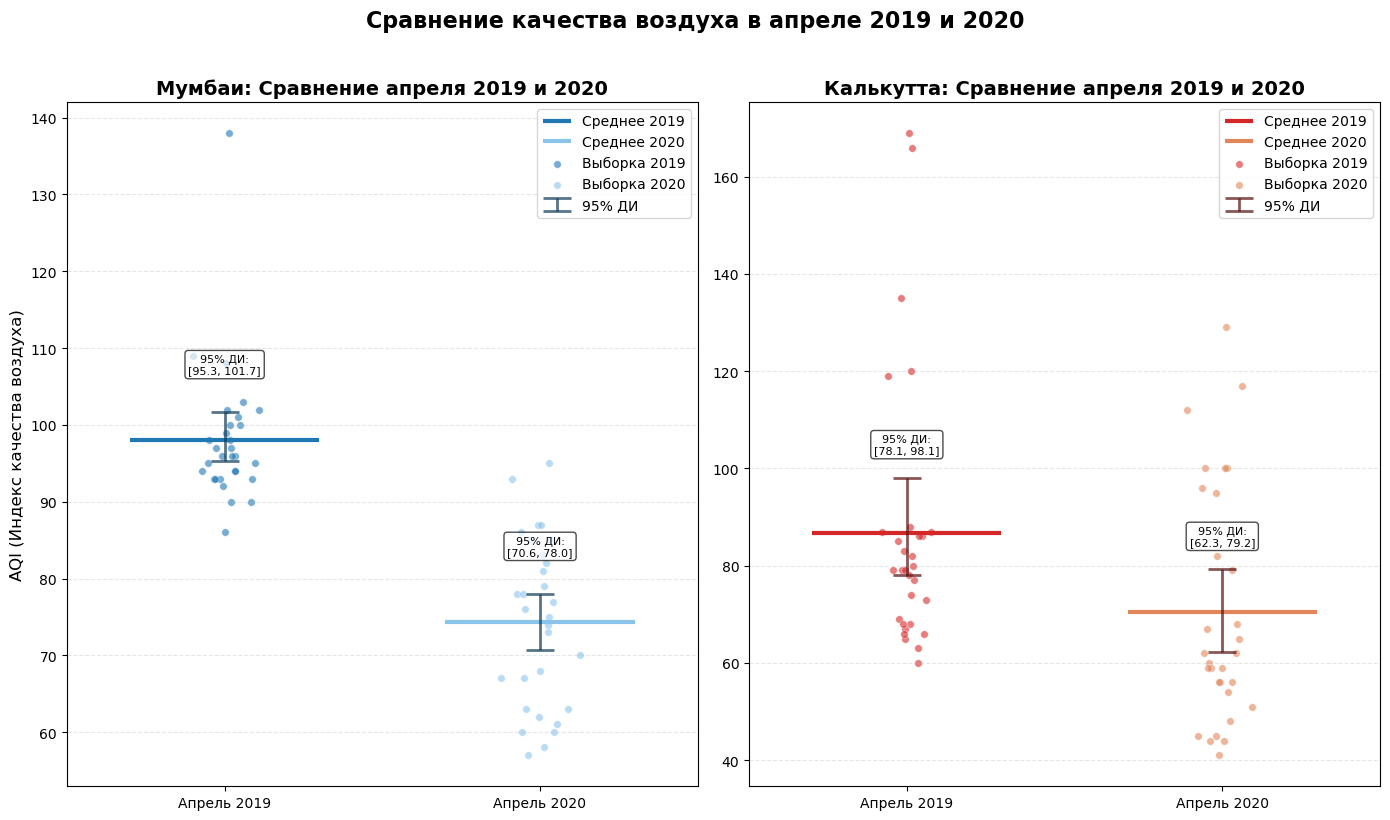

In [29]:
# Цвета для городов и лет
city_colors = {
    'Mumbai': {
        'ci_color':'#0f3a57',
        'year19': '#1f77b4',  
        'year20': '#8bc4eb'  
    },
    'Kolkata': {
        'ci_color':'#561010',
        'year19': '#d62728',
        'year20': '#e18659'
    }
}

# Создаём фигуру с двумя подграфиками
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8))

# --- ГРАФИК ДЛЯ МУМБАИ ---
x_positions_mumbai = [1, 2]  # позиции для двух лет


# линии средней
ax1.hlines(
    y=mumbai_years19['means'], 
    xmin=x_positions_mumbai[0] - 0.3, 
    xmax=x_positions_mumbai[0] + 0.3,
    colors=city_colors['Mumbai']['year19'],
    linewidth=3,
    label='Среднее 2019'
)
ax1.hlines(
    y=mumbai_years20['means'], 
    xmin=x_positions_mumbai[1] - 0.3, 
    xmax=x_positions_mumbai[1] + 0.3,
    colors=city_colors['Mumbai']['year20'],
    linewidth=3,
    label='Среднее 2020'
)

# точки выборки с джиттером (случайным смещением)
x_jitter = np.random.normal(x_positions_mumbai[0], 0.05, size=len(mumbai_year19_sample))
ax1.scatter(
    x_jitter,
    mumbai_year19_sample,
    color=city_colors['Mumbai']['year19'],
    alpha=0.6,
    s=30,
    edgecolor='white',
    linewidth=0.5,
    label='Выборка 2019'
)
x_jitter = np.random.normal(x_positions_mumbai[1], 0.05, size=len(mumbai_year20_sample))
ax1.scatter(
    x_jitter, 
    mumbai_year20_sample,
    color=city_colors['Mumbai']['year20'],
    alpha=0.6,
    s=30,
    edgecolor='white',
    linewidth=0.5,
    label='Выборка 2020'
)

# доверительные интервалы
ax1.errorbar(
    x_positions_mumbai[0], mumbai_years19['means'],
    yerr=[[mumbai_years19['means'].iloc[0] - mumbai_years19['ci_lower'].iloc[0]], 
          [mumbai_years19['ci_upper'].iloc[0] - mumbai_years19['means'].iloc[0]]],
    fmt='none',
    ecolor=city_colors['Mumbai']['ci_color'],
    capsize=10,
    capthick=2,
    linewidth=2,
    alpha=0.7,
    label='95% ДИ'
)
ax1.errorbar(
    x_positions_mumbai[1], mumbai_years20['means'],
    yerr=[[mumbai_years20['means'].iloc[0] - mumbai_years20['ci_lower'].iloc[0]], 
          [mumbai_years20['ci_upper'].iloc[0] - mumbai_years20['means'].iloc[0]]],
    fmt='none',
    ecolor=city_colors['Mumbai']['ci_color'],
    capsize=10,
    capthick=2,
    linewidth=2,
    alpha=0.7
)


# --- ГРАФИК ДЛЯ КАЛЬКУТТЫ ---
x_positions_kolkata = [1, 2]

# лини средних
ax2.hlines(
    y=kolkata_years19['means'], 
    xmin=x_positions_kolkata[0] - 0.3, 
    xmax=x_positions_kolkata[0] + 0.3,
    colors=city_colors['Kolkata']['year19'],
    linewidth=3,
    label='Среднее 2019'
)
ax2.hlines(
    y=kolkata_years20['means'], 
    xmin=x_positions_kolkata[1] - 0.3, 
    xmax=x_positions_kolkata[1] + 0.3,
    colors=city_colors['Kolkata']['year20'],
    linewidth=3,
    label='Среднее 2020'
)

# точки выборки с джиттером
x_jitter = np.random.normal(x_positions_kolkata[0], 0.05, size=len(kolkata_year19_sample))
ax2.scatter(
    x_jitter, 
    kolkata_year19_sample,
    color=city_colors['Kolkata']['year19'],
    alpha=0.6,
    s=30,
    edgecolor='white',
    linewidth=0.5,
    label='Выборка 2019'
)
x_jitter = np.random.normal(x_positions_kolkata[1], 0.05, size=len(kolkata_year20_sample))
ax2.scatter(
    x_jitter, 
    kolkata_year20_sample,
    color=city_colors['Kolkata']['year20'],
    alpha=0.6,
    s=30,
    edgecolor='white',
    linewidth=0.5,
    label='Выборка 2020'
)

# доверительные интервалы
ax2.errorbar(
    x_positions_kolkata[0], kolkata_years19['means'],
    yerr=[[kolkata_years19['means'].iloc[0] - kolkata_years19['ci_lower'].iloc[0]], 
          [kolkata_years19['ci_upper'].iloc[0] - kolkata_years19['means'].iloc[0]]],
    fmt='none',
    ecolor=city_colors['Kolkata']['ci_color'],
    capsize=10,
    capthick=2,
    linewidth=2,
    alpha=0.7,
    label='95% ДИ'
)
ax2.errorbar(
    x_positions_kolkata[1], kolkata_years20['means'],
    yerr=[[kolkata_years20['means'].iloc[0] - kolkata_years20['ci_lower'].iloc[0]], 
          [kolkata_years20['ci_upper'].iloc[0] - kolkata_years20['means'].iloc[0]]],
    fmt='none',
    ecolor=city_colors['Kolkata']['ci_color'],
    capsize=10,
    capthick=2,
    linewidth=2,
    alpha=0.7
)


# Настройка графика для Мумбаи
ax1.set_xlim(0.5, 2.5)
ax1.set_xticks(x_positions_mumbai)
ax1.set_xticklabels(['Апрель 2019', 'Апрель 2020'])
ax1.set_ylabel('AQI (Индекс качества воздуха)', fontsize=12)
ax1.set_title('Мумбаи: Сравнение апреля 2019 и 2020', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3, linestyle='--', axis='y')
ax1.legend(loc='upper right', fontsize=10)

# Добавляем значения доверительных интервалов
ci_text_y1 = mumbai_years19['ci_upper'].iloc[0] + 5
ci_text_y2 = mumbai_years20['ci_upper'].iloc[0] + 5
ax1.text(x_positions_mumbai[0], ci_text_y1, 
        f'95% ДИ:\n[{mumbai_years19['ci_lower'].iloc[0]:.1f}, {mumbai_years19['ci_upper'].iloc[0]:.1f}]',
        ha='center', fontsize=8, bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
ax1.text(x_positions_mumbai[1], ci_text_y2,
        f'95% ДИ:\n[{mumbai_years20['ci_lower'].iloc[0]:.1f}, {mumbai_years20['ci_upper'].iloc[0]:.1f}]',
        ha='center', fontsize=8, bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

# Настройка графика для Калькутты
ax2.set_xlim(0.5, 2.5)
ax2.set_xticks(x_positions_kolkata)
ax2.set_xticklabels(['Апрель 2019', 'Апрель 2020'])
ax2.set_title('Калькутта: Сравнение апреля 2019 и 2020', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3, linestyle='--', axis='y')
ax2.legend(loc='upper right', fontsize=10)

# Добавляем значения доверительных интервалов
ci_text_y1 = kolkata_years19['ci_upper'].iloc[0] + 5
ci_text_y2 = kolkata_years20['ci_upper'].iloc[0] + 5
ax2.text(x_positions_kolkata[0], ci_text_y1, 
        f'95% ДИ:\n[{kolkata_years19['ci_lower'].iloc[0]:.1f}, {kolkata_years19['ci_upper'].iloc[0]:.1f}]',
        ha='center', fontsize=8, bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
ax2.text(x_positions_kolkata[1], ci_text_y2,
        f'95% ДИ:\n[{kolkata_years20['ci_lower'].iloc[0]:.1f}, {kolkata_years20['ci_upper'].iloc[0]:.1f}]',
        ha='center', fontsize=8, bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))


plt.suptitle('Сравнение качества воздуха в апреле 2019 и 2020', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('air_quality.png')  # сохраняем
plt.show()

In [30]:
# Выводим статистику
print("\n" + "="*60)
print("СТАТИСТИКА ДЛЯ АПРЕЛЯ")
print("="*60)

print(f"\nМУМБАИ:")
print("  Апрель 2019:")
print(f"    Размер выборки: {len(mumbai_year19_sample)}")
print(f"    Среднее: {mumbai_years19['means'].iloc[0]:.2f}")
print(f"    Стд. отклонение: {np.std(mumbai_year19_sample):.2f}")
print(f"    95% ДИ: [{mumbai_years19['ci_lower'].iloc[0]:.2f}, {mumbai_years19['ci_upper'].iloc[0]:.2f}]")

print("\n  Апрель 2020:")
print(f"    Размер выборки: {len(mumbai_year20_sample)}")
print(f"    Среднее: {mumbai_years20['means'].iloc[0]:.2f}")
print(f"    Стд. отклонение: {np.std(mumbai_year20_sample):.2f}")
print(f"    95% ДИ: [{mumbai_years20['ci_lower'].iloc[0]:.2f}, {mumbai_years20['ci_upper'].iloc[0]:.2f}]")

# Проверка статистической значимости разницы
if not np.isnan(mumbai_years19['means'].iloc[0]) and not np.isnan(mumbai_years20['means'].iloc[0]):
    diff_mumbai = mumbai_years20['means'].iloc[0] - mumbai_years19['means'].iloc[0]
    print(f"\n  Разница (2020 - 2019): {diff_mumbai:.2f}")
    
    # Проверяем перекрытие доверительных интервалов
    if (mumbai_years19['ci_upper'].iloc[0] < mumbai_years20['ci_lower'].iloc[0]):
        print(f"  → ДИ не перекрываются: значимое увеличение AQI в 2020")
    elif (mumbai_years20['ci_upper'].iloc[0] < mumbai_years19['ci_lower'].iloc[0]):
        print(f"  → ДИ не перекрываются: значимое уменьшение AQI в 2020")
    else:
        print(f"  → ДИ перекрываются: разница статистически не значима")

print("\nКАЛЬКУТТА:")
print("  Апрель 2019:")
print(f"    Размер выборки: {len(kolkata_year19_sample)}")
print(f"    Среднее: {kolkata_years19['means'].iloc[0]:.2f}")
print(f"    Стд. отклонение: {np.std(kolkata_year19_sample):.2f}")
print(f"    95% ДИ: [{kolkata_years19['ci_lower'].iloc[0]:.2f}, {kolkata_years19['ci_upper'].iloc[0]:.2f}]")
    
print("\n  Апрель 2020:")
print(f"    Размер выборки: {len(kolkata_year20_sample)}")
print(f"    Среднее: {kolkata_years20['means'].iloc[0]:.2f}")
print(f"    Стд. отклонение: {np.std(kolkata_year20_sample):.2f}")
print(f"    95% ДИ: [{kolkata_years20['ci_lower'].iloc[0]:.2f}, {kolkata_years20['ci_upper'].iloc[0]:.2f}]")

if not np.isnan(kolkata_years19['means'].iloc[0]) and not np.isnan(kolkata_years20['means'].iloc[0]):
    diff_kolkata = kolkata_years20['means'].iloc[0] - kolkata_years19['means'].iloc[0]
    print(f"\n  Разница (2020 - 2019): {diff_kolkata:.2f}")
    
    if (kolkata_years19['ci_upper'].iloc[0] < kolkata_years20['ci_lower'].iloc[0]):
        print(f"  → ДИ не перекрываются: значимое увеличение AQI в 2020")
    elif (kolkata_years20['ci_upper'].iloc[0] < kolkata_years19['ci_lower'].iloc[0]):
        print(f"  → ДИ не перекрываются: значимое уменьшение AQI в 2020")
    else:
        print(f"  → ДИ перекрываются: разница статистически не значима")

    



СТАТИСТИКА ДЛЯ АПРЕЛЯ

МУМБАИ:
  Апрель 2019:
    Размер выборки: 30
    Среднее: 98.07
    Стд. отклонение: 8.91
    95% ДИ: [95.30, 101.70]

  Апрель 2020:
    Размер выборки: 30
    Среднее: 74.33
    Стд. отклонение: 10.69
    95% ДИ: [70.63, 78.03]

  Разница (2020 - 2019): -23.73
  → ДИ не перекрываются: значимое уменьшение AQI в 2020

КАЛЬКУТТА:
  Апрель 2019:
    Размер выборки: 30
    Среднее: 86.80
    Стд. отклонение: 27.28
    95% ДИ: [78.13, 98.07]

  Апрель 2020:
    Размер выборки: 30
    Среднее: 70.37
    Стд. отклонение: 24.11
    95% ДИ: [62.30, 79.20]

  Разница (2020 - 2019): -16.43
  → ДИ перекрываются: разница статистически не значима


**Задание 6.**

Сделайте выводы. Что можно сказать про доверительные интервалы в каждом из случаев? Какие прикладные выводы о загрязнении воздуха можно сделать из Ваших результатов?

**Вывод:**

На основе предоставленных данных можно сделать следующие статистические и прикладные выводы.

**Анализ доверительных интервалов (ДИ)**

**Мумбаи:**

**Анализ:** Доверительные интервалы для 2019 года [95.33, 102.00] и для 2020 года [70.70, 77.87] не пересекаются. Верхняя граница ДИ 2020 года (77.87) значительно ниже нижней границы ДИ 2019 года (95.33).

**Вывод:** Это свидетельствует о статистически значимом различии между средними значениями AQI в апреле 2019 и 2020 года. Мы можем быть уверены, что снижение уровня загрязнения в 2020 году не является случайностью, а отражает реальное изменение ситуации. Возможно это связано с локдауном во время пандемии в 2020 (апрель 2020 года — начало строгого локдауна в Индии). В Мумбаи карантинные меры привели к однозначному и статистически подтвержденному улучшению качества воздуха. Снижение AQI почти на 24 пункта — это существенный результат для здоровья населения.

**Калькутта:**

**Анализ:** Доверительные интервалы для 2019 года [78.07, 96.71] и для 2020 года [62.33, 78.97] перекрываются. Интервал 2020 года заходит в зону интервала 2019 года (значение 78.97 из 2020 года попадает в диапазон 2019 года, который начинается с 78.07).

**Вывод:** Несмотря на то, что среднее значение снизилось (с 86.80 до 70.37), это изменение не является статистически значимым на 95% уровне доверия. Высокое стандартное отклонение (27.28 и 24.11) указывает на сильный разброс данных, из-за чего мы не можем с уверенностью утверждать, что снижение AQI в 2020 году было закономерным, а не вызвано естественными колебаниями или особенностями выборки.

В Калькутте средний уровень AQI тоже упал, но из-за высокой вариабельности данных (нестабильности погоды, особенно локальных источников выбросов или других факторов) мы не можем статистически доказать, что это снижение связано именно с изменением условий (например, локдауном), а не с обычными колебаниями.

**Прикладные выводы о загрязнении воздуха**

**Проблема "шума" в данных (Калькутта):**

Высокое стандартное отклонение в Калькутте (особенно в 2019 году: 27.28 против 8.91 в Мумбаи) говорит о том, что уровень загрязнения там был крайне неоднороден в течение месяца. Возможно, были дни с очень чистым воздухом и дни с катастрофическими пиками. Из-за этого "шума" даже хорошее падение среднего (на 16.43) "теряется" и не позволяет сделать уверенный вывод. В Мумбаи ситуация была более стабильной, поэтому улучшение видно четче.

**Разные исходные условия:**

Интересно, что в 2019 году уровень загрязнения в Мумбаи (98.07) был выше, чем в Калькутте (86.80), хотя разброс в Калькутте был больше. К 2020 году города почти сравнялись (74.33 против 70.37), но из-за статистической погрешности в Калькутте мы не можем утверждать, что они стали "одинаково чистыми".

**Итог:** Можно уверенно говорить о положительном влиянии изменений 2020 года (вероятно, локдауна) на воздух в Мумбаи. Для Калькутты требуются дополнительные исследования или больший объем данных, так как статистический анализ не позволяет отделить эффект от случайных колебаний, несмотря на визуально заметное падение среднего уровня AQI.

Можно еще дать такую интерпретацию, что если ДИ не пересекаются, 
то значит в каком то городе значение качества воздуха стат значимо лучше, чем в другом.
По хорошему можно было бы из одного значения вычесть другое, посторить доверительный интервал для разницы  разности и посмотреть пересекает ли он ноль, вот это формально правильно. Но можно и так пока на глаз прикидывать если два ДИ на графике не пересекаются , то это уже говорит о том что где-то воздух прям сильно лучше чем в другом месте. Если ДИ пересевкаются, то это говорит о том, что не понятно хуже или лучше, может и так и так.

Тут именно интересно посмотреть как ДИ относительно друг другу ложаться.